# 05 · Final evaluation, explainability and uncertainty
The test split is used **once**, for the already-selected model and the median baseline.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "carprice").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from carprice.config import load_settings
S = load_settings()
P = S.paths
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.float_format", "{:,.3f}".format)
def show_fig(name):
    display(Image(filename=str(P.figures / name), width=900))
def md(text): display(Markdown(text))


In [2]:
tm = json.load(open(P.metrics / "test_metrics.json"))
m, b = tm["test_metrics"], tm["median_baseline_test_metrics"]
keys = ["mae_inr","mse_inr2","rmse_inr","r2","adj_r2","medae_inr","mape_pct","smape_pct","rmsle","explained_variance","max_error_inr","mbe_inr","mase"]
display(pd.DataFrame({"selected model": {k: m[k] for k in keys}, "median baseline": {k: b[k] for k in keys}}))
md(f"**Headline:** MAE ₹{m['mae_inr']:,.0f} (95% bootstrap CI ₹{m['mae_inr_ci95'][0]:,.0f}–₹{m['mae_inr_ci95'][1]:,.0f}), R² {m['r2']:.2f} "
   f"(CI {m['r2_ci95'][0]:.2f}–{m['r2_ci95'][1]:.2f}). The baseline MAE is ₹{b['mae_inr']:,.0f}, so the model removes about {(1-m['mae_inr']/b['mae_inr'])*100:.0f}% of the error. "
   f"With only {m['n']} test rows the confidence intervals are wide - treat differences of a few percent as noise.")
md("Metric meanings and limitations: `reports/model_reports/metric_definitions.md`. Notes: **adjusted R²** is not meaningful for an RBF-kernel SVR with ~1.6× more inputs than rows; "
   "**MAPE** is inflated by cheap cars; **MASE** here is MAE relative to the constant-median predictor (a skill score).")

,selected model,median baseline
mae_inr,"102,386.923","209,637.324"
mse_inr2,"47,653,796,242.151","133,436,670,719.517"
rmse_inr,"218,297.495","365,289.845"
r2,0.622,-0.057
adj_r2,-0.394,NaN
medae_inr,"42,095.585","140,001.000"
mape_pct,29.252,86.219
smape_pct,25.139,57.734
rmsle,0.378,0.804
explained_variance,0.623,0.000


**Headline:** MAE ₹102,387 (95% bootstrap CI ₹74,227–₹137,105), R² 0.62 (CI 0.19–0.79). The baseline MAE is ₹209,637, so the model removes about 51% of the error. With only 145 test rows the confidence intervals are wide - treat differences of a few percent as noise.

Metric meanings and limitations: `reports/model_reports/metric_definitions.md`. Notes: **adjusted R²** is not meaningful for an RBF-kernel SVR with ~1.6× more inputs than rows; **MAPE** is inflated by cheap cars; **MASE** here is MAE relative to the constant-median predictor (a skill score).

## Residuals

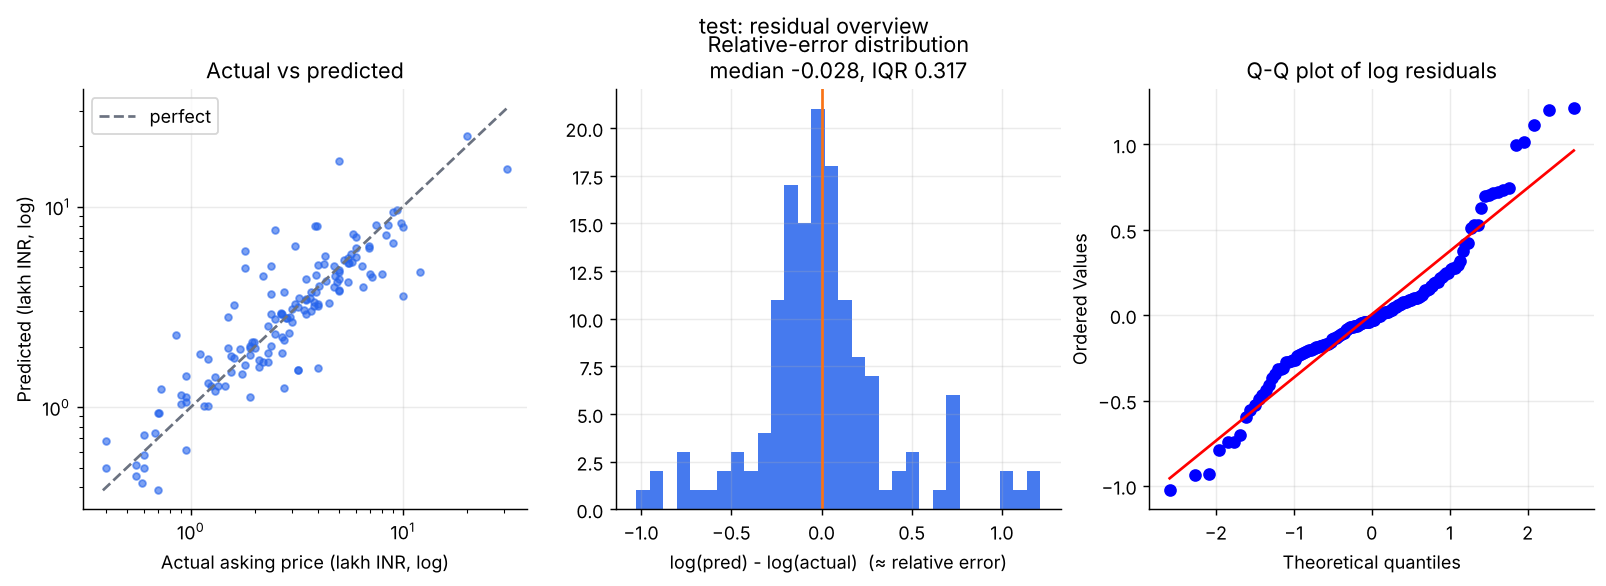

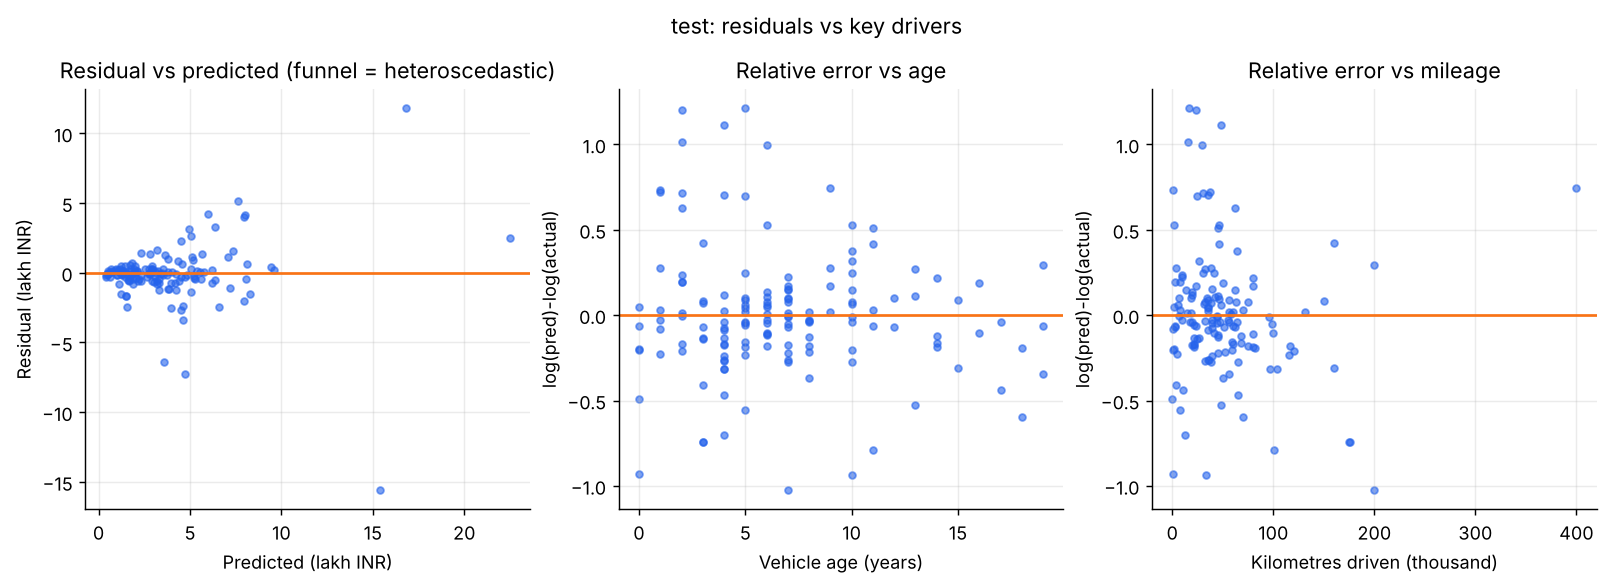

In [3]:
show_fig("test_residual_overview.png"); show_fig("test_residual_vs_features.png")

## Error by segment (price range, brand, age, mileage, fuel, rare/expensive vehicles)

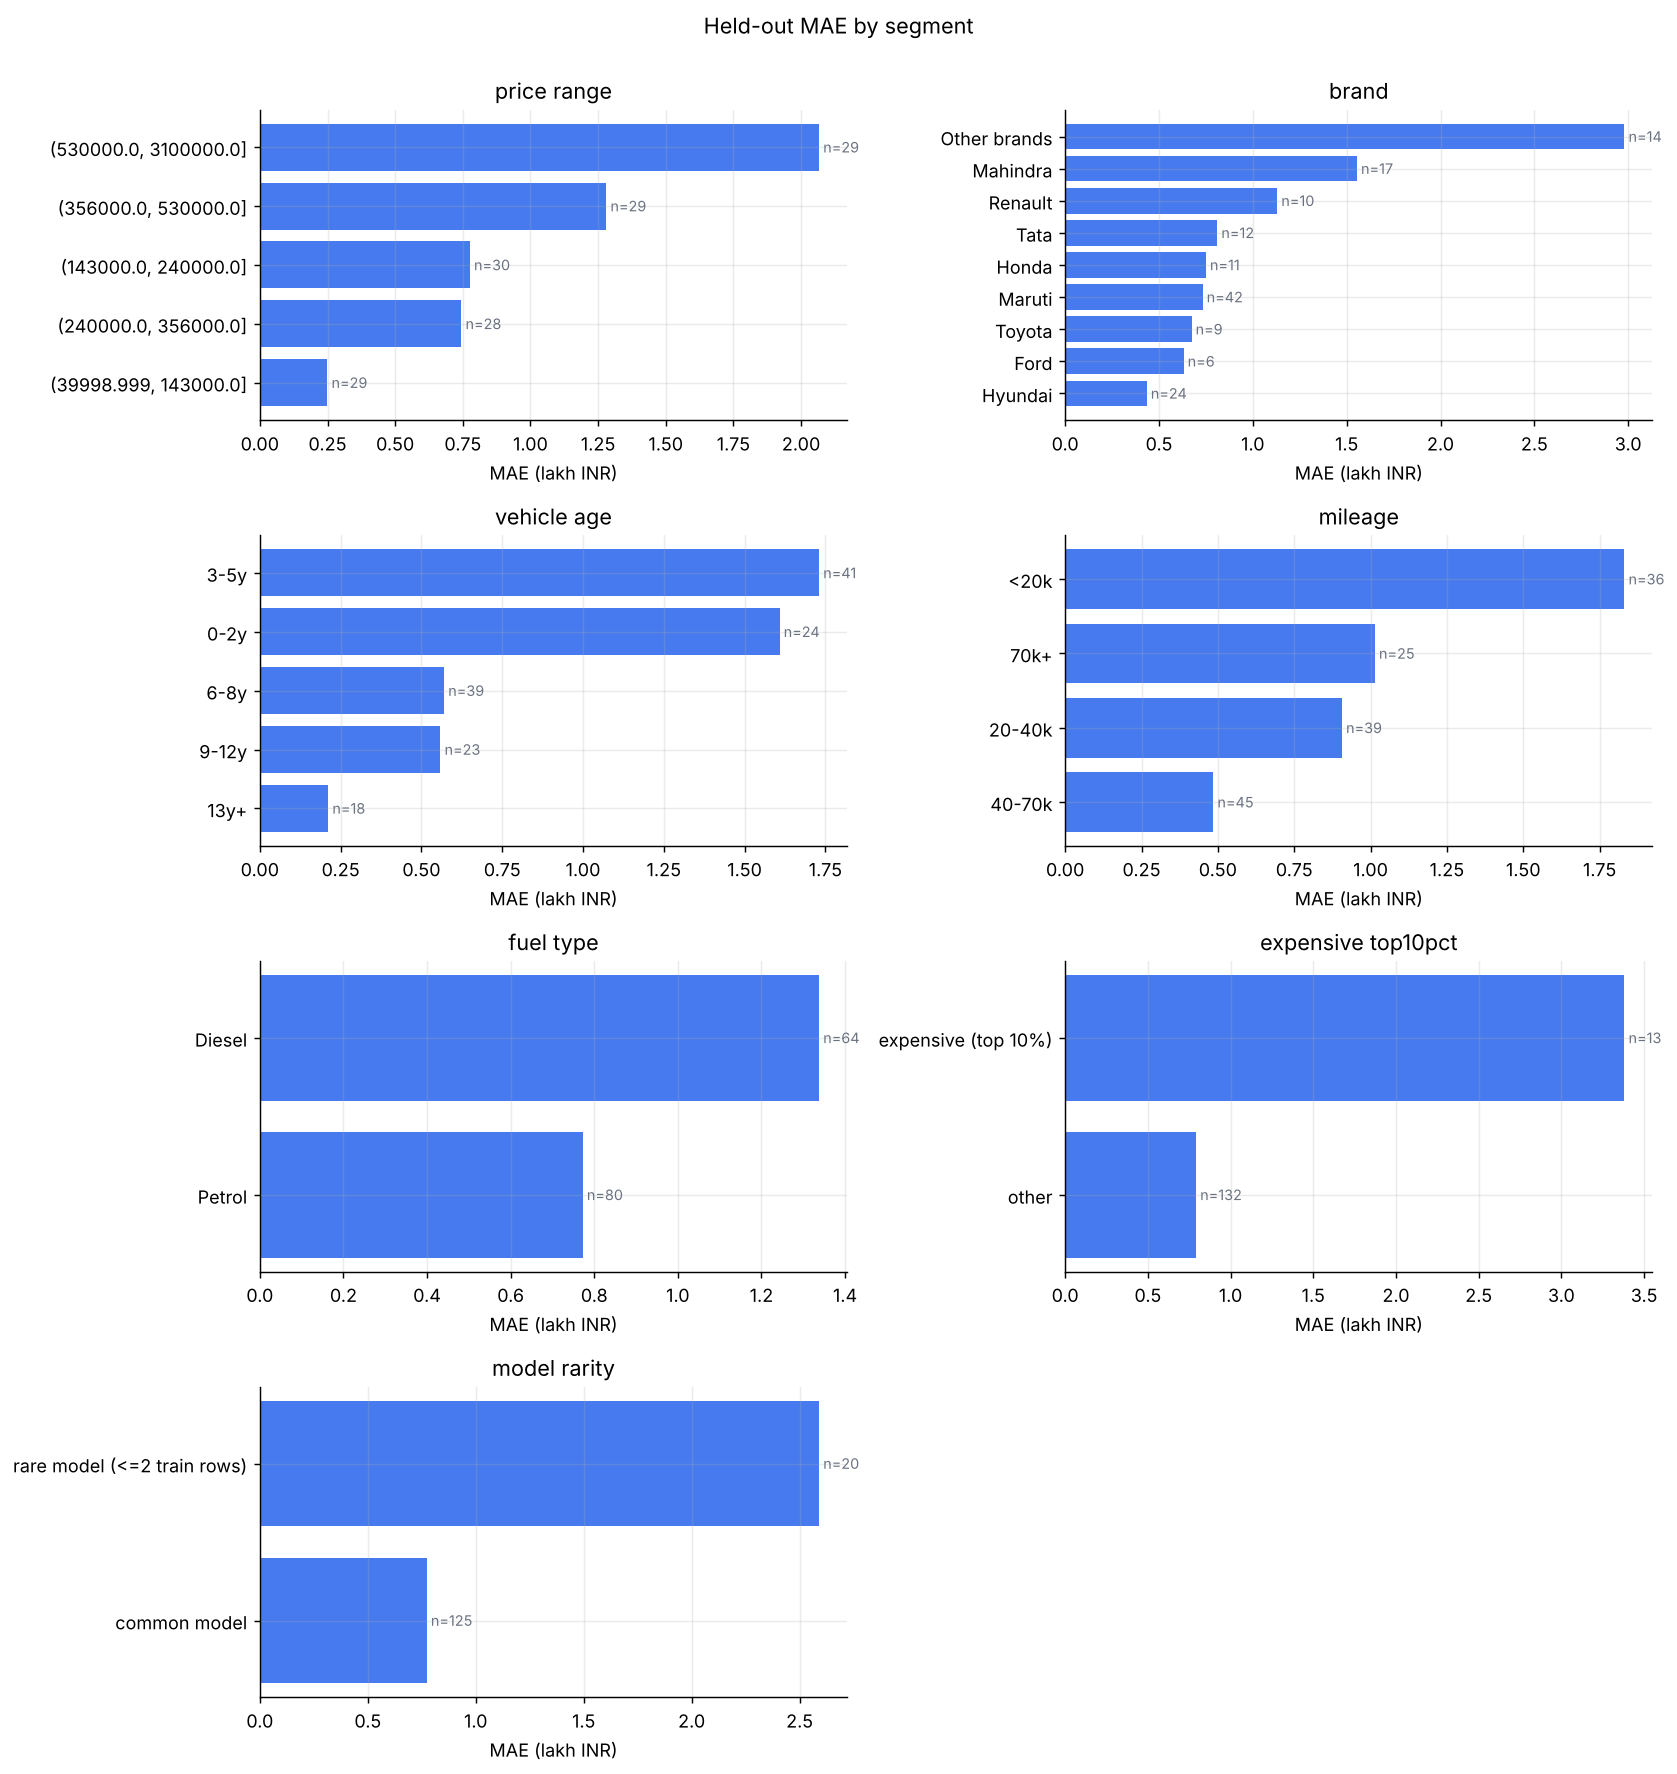

,segment_type,segment,n,mae_inr,medae_inr,mape_pct,mbe_inr,rmsle
0,price_range,"(356000.0, 530000.0]",29,"128,052.562","67,518.780",29.114,"41,412.422",0.375
1,price_range,"(143000.0, 240000.0]",30,"77,628.286","38,308.726",40.322,"48,136.338",0.428
2,price_range,"(240000.0, 356000.0]",28,"74,491.190","30,857.515",26.091,"9,812.480",0.378
3,price_range,"(39998.999, 143000.0]",29,"24,981.964","14,234.943",30.361,"14,175.083",0.338
4,price_range,"(530000.0, 3100000.0]",29,"206,672.436","109,813.557",19.880,"-160,388.411",0.363
5,brand,Other brands,14,"298,012.318","53,152.494",44.970,"-45,237.133",0.513
6,brand,Maruti,42,"73,230.795","31,343.175",28.703,"-6,435.678",0.375
7,brand,Mahindra,17,"155,470.567","61,526.953",46.383,"55,462.105",0.488
8,brand,Renault,10,"113,006.338","93,381.298",18.831,"-112,529.624",0.283
9,brand,Hyundai,24,"43,473.327","19,334.048",13.789,"-12,636.661",0.281


In [4]:
seg = pd.read_csv(P.metrics / "test_segment_errors.csv")
show_fig("test_error_by_segment.png")
display(seg)

## Prediction intervals - validated on held-out data

**conformal**: target 90%, empirical coverage **86.2% ± 2.9%**, median width ₹384,981 (≈ 106% of the price), mean interval score 801,946

,coverage,median_width_inr,n
predicted_price_tier,,,
high,0.776,"666,519.350",49.000
low,0.896,"157,996.773",48.000
mid,0.917,"382,680.080",48.000


,coverage,median_width_inr,n
vehicle_age,,,
0-2y,0.708,"605,408.491",24.000
13y+,0.944,"91,178.872",18.000
3-5y,0.829,"505,818.881",41.000
6-8y,0.949,"401,212.382",39.000
9-12y,0.870,"212,759.414",23.000


**quantile_gbm**: target 90%, empirical coverage **86.2% ± 2.9%**, median width ₹406,335 (≈ 116% of the price), mean interval score 812,896

,coverage,median_width_inr,n
predicted_price_tier,,,
high,0.837,"523,068.053",49.000
low,0.896,"360,571.647",48.000
mid,0.854,"382,082.678",48.000


,coverage,median_width_inr,n
vehicle_age,,,
0-2y,0.792,"554,356.900",24.000
13y+,0.889,"392,514.222",18.000
3-5y,0.902,"504,121.132",41.000
6-8y,0.795,"319,600.771",39.000
9-12y,0.957,"341,154.420",23.000


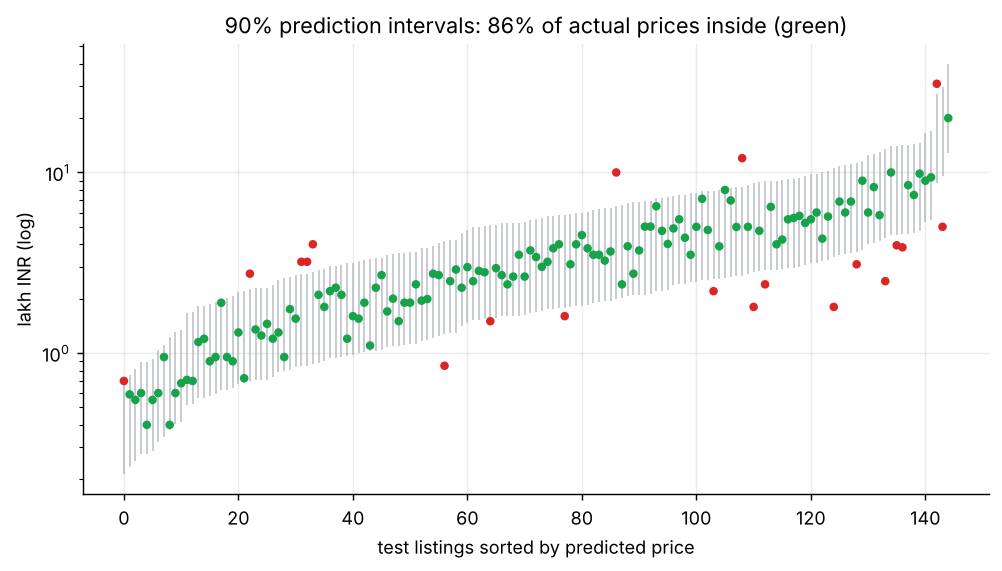

Intervals are conformal PREDICTION intervals for an individual listing's asking price, not confidence intervals for a mean. Empirical coverage on held-out data is reported with its binomial standard error because n_test is small.

**Honest reading:** marginal coverage is close to (and statistically consistent with) the 90% target, but conditional coverage is weaker for expensive and newer cars, and the intervals are wide because the model's typical relative error is large. Both methods behave similarly; conformal is kept for its finite-sample guarantee and simplicity.

In [5]:
ir = json.load(open(P.metrics / "interval_report.json"))
for k in ["conformal", "quantile_gbm"]:
    d = ir[k]
    md(f"**{k}**: target {d['target_coverage']:.0%}, empirical coverage **{d['empirical_coverage']:.1%} ± {d['coverage_se']:.1%}**, median width ₹{d['median_width_inr']:,.0f} "
       f"(≈ {d['median_relative_width_pct']:.0f}% of the price), mean interval score {d['mean_interval_score']:,.0f}")
    for g, rows in d["by_group"].items():
        display(pd.DataFrame(rows).T.rename_axis(g).round(3))
show_fig("test_prediction_intervals.png")
md(ir["statement"])
md("**Honest reading:** marginal coverage is close to (and statistically consistent with) the 90% target, but conditional coverage is weaker for expensive and newer cars, "
   "and the intervals are wide because the model's typical relative error is large. Both methods behave similarly; conformal is kept for its finite-sample guarantee and simplicity.")

## Explainability (model behaviour, not causation)

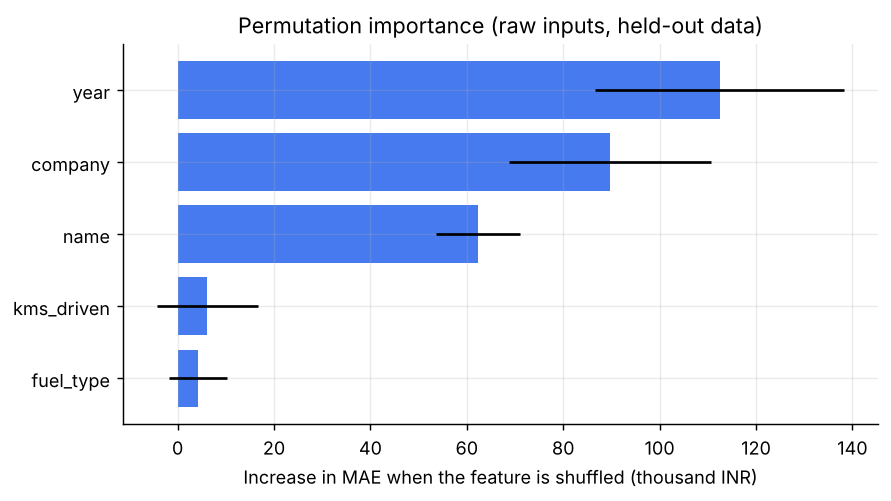

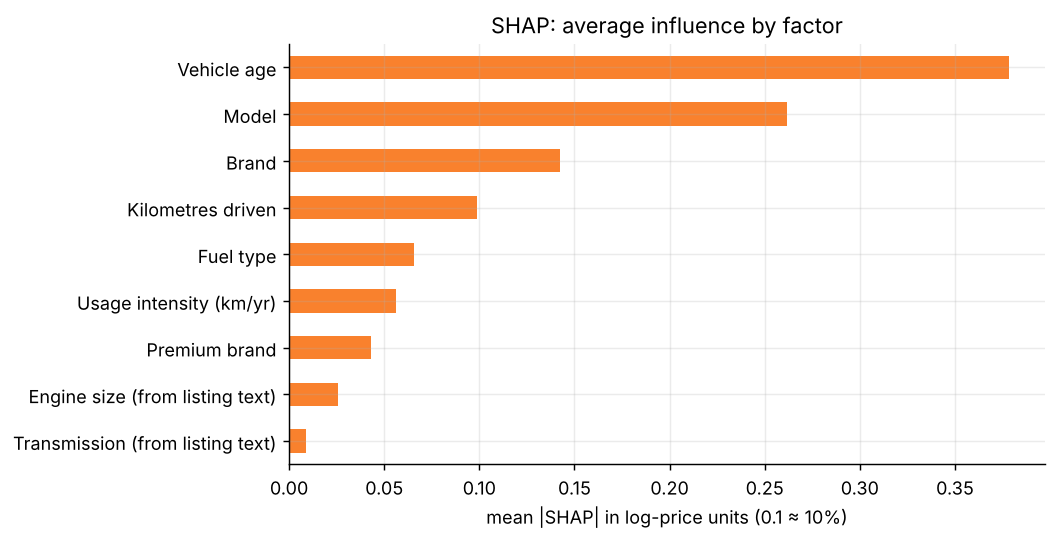

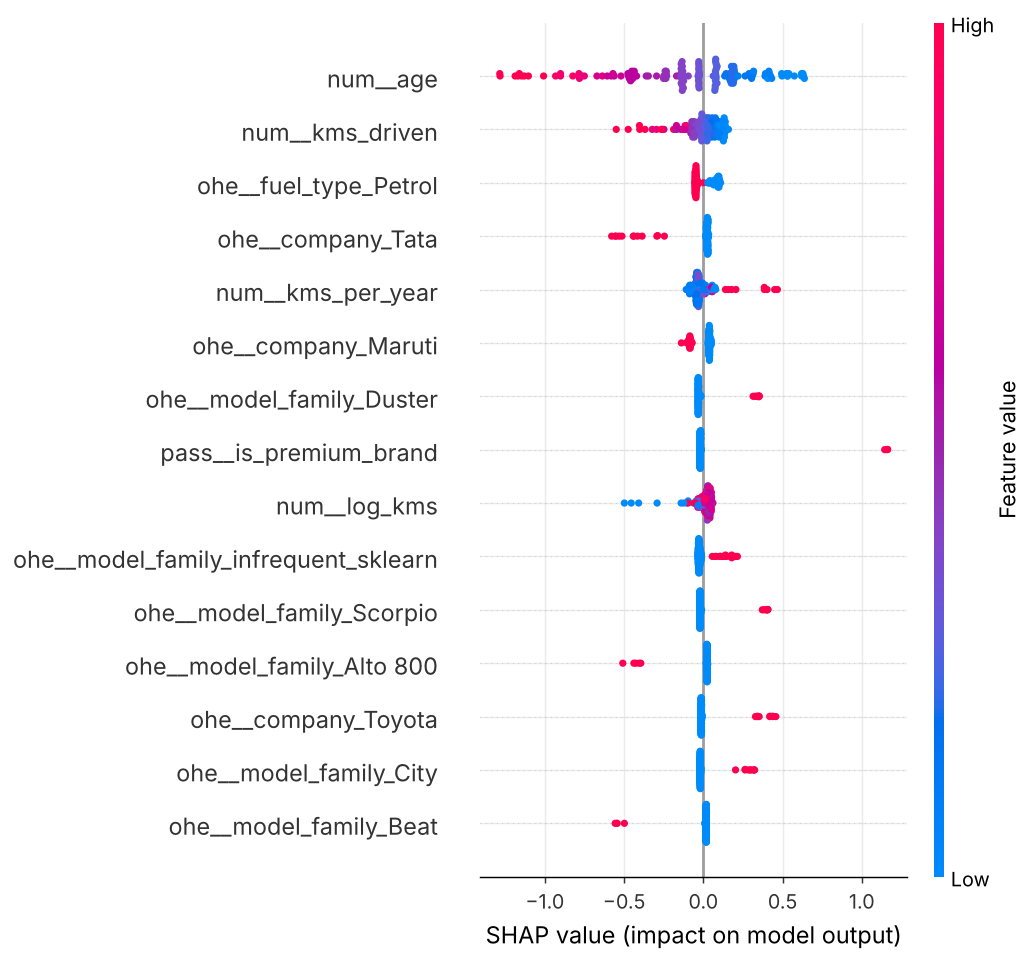

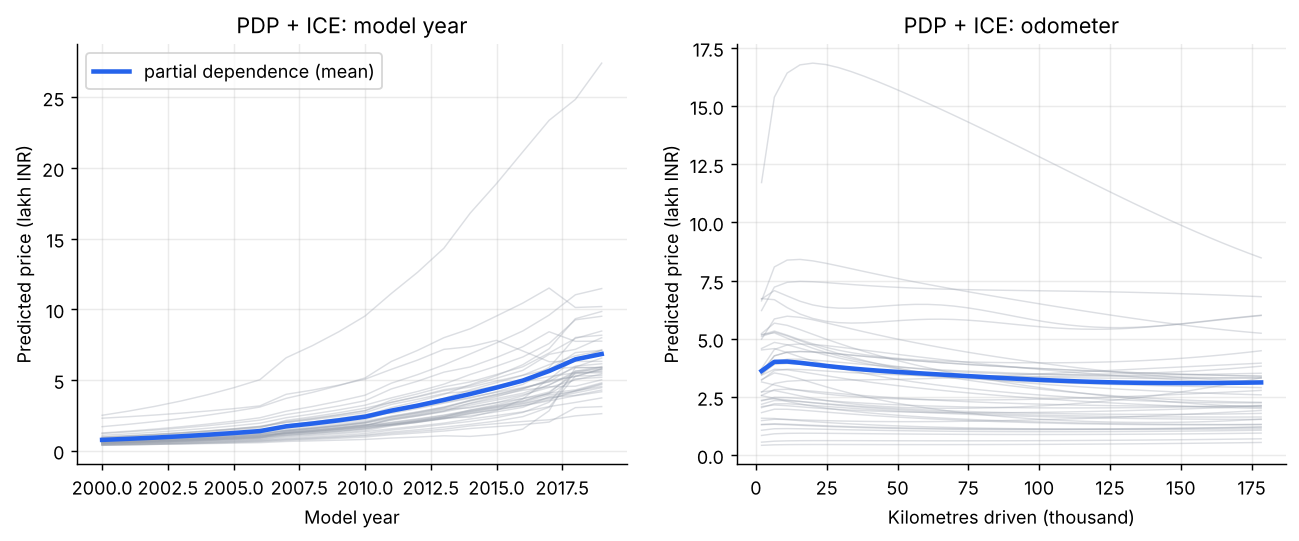

In [6]:
show_fig("permutation_importance.png"); show_fig("shap_factor_importance.png"); show_fig("shap_summary_beeswarm.png"); show_fig("pdp_ice_year_kms.png")

In [7]:
for ex in json.load(open(P.metrics / "example_explanations.json"))[:3]:
    i = ex["input"]
    md(f"**{i['name']} ({i['year']}, {i['kms_driven']:,.0f} km, {i['fuel_type']})** → predicted ₹{ex['predicted_inr']:,.0f} (actual ₹{ex['actual_inr']:,.0f})")
    display(pd.DataFrame(ex["top_factors"])[["factor","direction","pct_effect","approx_inr_effect"]])

**Ford Figo Petrol LXI (2011, 75,000 km, Petrol)** → predicted ₹145,754 (actual ₹175,000)

,factor,direction,pct_effect,approx_inr_effect
0,Model,lowers price,-34.742,"-77,595.585"
1,Fuel type,lowers price,-9.623,"-15,518.904"
2,Kilometres driven,lowers price,-5.598,"-8,643.420"
3,Premium brand,lowers price,-3.894,"-5,905.749"
4,Brand,raises price,3.805,"5,342.046"


**Toyota Etios G (2013, 42,000 km, Petrol)** → predicted ₹294,068 (actual ₹265,000)

,factor,direction,pct_effect,approx_inr_effect
0,Brand,raises price,51.186,"99,560.758"
1,Model,lowers price,-29.252,"-121,588.935"
2,Vehicle age,raises price,22.664,"54,332.521"
3,Fuel type,lowers price,-11.218,"-37,155.982"
4,Premium brand,lowers price,-3.925,"-12,013.303"


**Maruti Suzuki Wagon R (2012, 44,000 km, Petrol)** → predicted ₹197,452 (actual ₹199,999)

,factor,direction,pct_effect,approx_inr_effect
0,Model,lowers price,-11.448,"-25,525.746"
1,Brand,lowers price,-10.237,"-22,518.907"
2,Fuel type,lowers price,-9.968,"-21,861.860"
3,Vehicle age,raises price,9.767,"17,568.985"
4,Premium brand,lowers price,-3.934,"-8,085.774"


## Model card

In [8]:
md((P.model_reports / "MODEL_CARD.md").read_text())

# Model card - used-car asking-price estimator

**Version:** `1.0.0+20261101013441.189781cd`   **Model:** `svr` (tuned)   **Feature set:** `base_plus_parsed`

## Intended use
Estimate the **asking price in INR** of a used passenger car in the Indian classified-listing market, with a
90% prediction interval, as decision support for sellers/buyers/analysts.
It is **not** an appraisal, transaction-price or ex-showroom-price model, and has no knowledge of vehicle condition,
accident history, city, or listing date.

## Data
quikr - 581 training / 145 held-out listings after cleaning (892 raw rows).
Snapshot year: 2019 (prices are circa that year; **not inflation-adjusted to today**). Licence: Not stated. The CSV is a scrape of public Quikr classified listings redistributed through the author's own repository. Treat as educational/portfolio use only; do not redistribute commercially. Verify terms before any commercial use.

## Held-out performance (test split, evaluated once)
| metric | model | median baseline |
|---|---:|---:|
| MAE (INR) | 102,387 (95% CI 74,227-137,105) | 209,637 |
| RMSE (INR) | 218,297 | 365,290 |
| R2 | 0.622 (95% CI 0.19-0.79) | -0.057 |
| median abs error (INR) | 42,096 | 140,001 |
| RMSLE | 0.378 | 0.804 |
| MAPE % | 29.3 | 86.2 |

## Prediction intervals
Mondrian conformal on log-error; target coverage 90%, **empirical test coverage 86.2%
(+/- 2.9% s.e., n=145)**, median relative width 106%.
Guarantee is marginal and assumes new listings resemble the training data.

## Limitations
- Small dataset (<1k rows); rare models and luxury brands are poorly covered - expect wider real errors there.
- No condition, location, owner-count, transmission or engine fields in this source; only partial hints parsed from listing text.
- Asking prices, circa 2019. Using the model for current-year valuation without recalibration is invalid.
- Explanations (SHAP) describe model behaviour, not causal effects.


## Experiment tracking (MLflow)

In [9]:
try:
    import mlflow
    mlflow.set_tracking_uri(f"sqlite:///{P.artifacts/'mlruns'/'mlflow.db'}")
    runs = mlflow.search_runs(experiment_names=[S.cfg["project"]["name"]])
    display(runs[[c for c in runs.columns if c.startswith(("params.model","params.variant","params.config_hash","metrics.test_mae","metrics.test_r2","metrics.interval"))]])
except Exception as e:
    print("MLflow not available here:", e)

2026/11/01 06:42:35 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /usr/local/lib/python3.13/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,metrics.interval_coverage,metrics.test_r2,metrics.test_mae_inr,params.model,params.variant,params.config_hash
0,0.862,0.622,"102,386.923",svr,base_plus_parsed,13c99b9591e56181
